# La batería de validación sobre una escalera de modelos: discriminación, calibración y estabilidad

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 y 02 de este tema, y el cuaderno 04 del tema 01
- **Tiempo de lectura:** unos 60 minutos

## Objetivos

Al terminar este cuaderno puedes:

- leer la batería versionada de C01, 187 filas de prueba sobre ocho modelos, como una sola tabla: cuáles de los 15 ids de prueba llevan umbral y cuáles solo describen, y qué filas pertenecen al portafolio y cuáles a un grado;
- recalcular una fila a nivel de grado, una fila a nivel de portafolio y un estadístico de Hosmer-Lemeshow desde las tablas versionadas de grados y de confiabilidad, y mostrar que son iguales a las filas versionadas;
- leer juntas la discriminación (AUC, DeLong contra la tarjeta de puntaje, AUC contra desarrollo), la calibración (pruebas de nivel y de ajuste) y la estabilidad (PSI), y decir por qué el mismo modelo puede estar verde en una familia y ámbar en otra;
- ver qué pruebas detectan una deriva de las entradas y cuáles un cambio de la tasa de incumplimiento, con las dos variantes desplazadas.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La siguiente celda importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

El caso es otra vez C01: las 9.000 tarjetas reservadas de Taiwán puntuadas por los ocho modelos de la escalera (UCI Taiwán, Yeh 2009, CC BY 4.0, clase de licencia `mirror-allowed`, https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients). Tres archivos versionados contienen la batería:

- `data/derived/C01/holdout.json`: la escalera (`model`), la batería (`tests`, una fila por prueba, modelo y segmento), y por modelo la tabla de grados, los tramos de confiabilidad y la curva ROC (`outputs.rungs`).
- `data/derived/C01/drift-moderate.json` y `data/derived/C01/prior-shift.json`: los mismos modelos y la misma batería sobre las mismas tarjetas tras una **perturbación sintética solo del conjunto de evaluación**: una deriva moderada de las entradas, y un cambio de la tasa base que multiplica por 1,5 la tasa de incumplimiento (el diseño del caso en `docs/design/SDD.md`: los desplazamientos se rotulan sintéticos y nunca tocan el ajuste). Muestran qué nota cada prueba.

La siguiente celda carga los tres archivos e imprime los escalones, con el título que el archivo da en este idioma.

In [2]:
# Cargar los tres archivos versionados e imprimir los escalones de la escalera
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C01"
holdout = json.loads((derived / "holdout.json").read_text(encoding="utf-8"))
drift = json.loads((derived / "drift-moderate.json").read_text(encoding="utf-8"))
prior = json.loads((derived / "prior-shift.json").read_text(encoding="utf-8"))

LANG = "es"
# Los valores de luz del motor, nombrados en este idioma
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "s/l"}
rungs = [m["id"] for m in holdout["model"]]
for m in holdout["model"]:
    print(f"{m['id']:14s} {m['title'][LANG]}")
print("calculado por riskvalidation", holdout["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
for name, doc in (("holdout", holdout), ("drift-moderate", drift), ("prior-shift", prior)):
    print(f"{name:15s} tarjetas {doc['outputs']['n']} | incumplimientos {doc['outputs']['defaults']} | filas de prueba {len(doc['tests'])}")


P0-constant    PD constante
P0-single      Una variable (PAY_0)
P1-scorecard   Scorecard logística WoE
P2a-l1         Regresión logística L1 sobre WoE
P2b-pltr       Regresión logística penalizada con árboles (PLTR)
P3-ebm         Máquina de boosting explicable (GA2M)
P4-lightgbm    Gradient boosting monótono (LightGBM)
P4-xgboost     Gradient boosting monótono (contraste con XGBoost)
calculado por riskvalidation 0.4.3 | instalado 0.9.0
holdout         tarjetas 9000 | incumplimientos 1991 | filas de prueba 187
drift-moderate  tarjetas 9000 | incumplimientos 2316 | filas de prueba 186
prior-shift     tarjetas 9000 | incumplimientos 2986 | filas de prueba 186


## Método

### Paso 1: una tabla de pruebas, dos tipos de fila

Cada fila de `tests` es un `TestResult` del motor: un id de prueba, un modelo, un segmento, el estadístico, el valor p o la métrica, y la luz que dio la política. El **segmento** dice de qué trata la fila: `portfolio` para toda la muestra reservada, un grado (`G05`, `G06`, ...) para las tarjetas de un grado, y `characteristic:<nombre>` para una variable de entrada de las pruebas de estabilidad. La **política** decide qué pruebas tienen luz: una prueba con umbral se colorea desde su valor p (ámbar bajo 0,05, rojo bajo 0,01 en la política por defecto); una prueba descriptiva (AUC, KS, Brier, ECE) mide y no recibe luz, porque las instrucciones del ECB y el documento de trabajo que las definen no fijan umbrales. La siguiente celda cuenta las filas versionadas por prueba y por tipo de segmento, y marca para qué pruebas la política por defecto tiene un umbral.

In [3]:
# Contar las filas versionadas por id de prueba y por tipo de segmento, y marcar las pruebas para las que la política por defecto tiene umbral
policy = rv.default_policy()
tests = holdout["tests"]


def kind_of(segment):
    return "portfolio" if segment == "portfolio" else ("característica" if segment.startswith("characteristic:") else "grado")


ids = sorted({t["test_id"] for t in tests})
print(f"{'test':22s} {'filas':>5s} {'portfolio':>9s} {'grado':>7s} {'caract.':>7s}  umbral en la política")
for test_id in ids:
    rows = [t for t in tests if t["test_id"] == test_id]
    counts = [sum(kind_of(t["segment"]) == k for t in rows) for k in ("portfolio", "grado", "característica")]
    print(f"{test_id:22s} {len(rows):5d} {counts[0]:9d} {counts[1]:7d} {counts[2]:7d}  {si_no(test_id in policy.thresholds)}")
print("filas en total:", len(tests), "| ids de prueba:", len(ids), "| modelos:", len(rungs))


test                   filas portfolio   grado caract.  umbral en la política
disc.auc                   8         8       0       0  no
disc.auc_vs_initial        7         7       0       0  sí
disc.delong                6         6       0       0  sí
disc.ks                    7         7       0       0  no
pd.binomial                8         8       0       0  sí
pd.binomial_vasicek        8         8       0       0  sí
pd.brier                   8         8       0       0  no
pd.chi2_grades             7         7       0       0  sí
pd.ece                     8         8       0       0  no
pd.hosmer_lemeshow         7         7       0       0  sí
pd.jeffreys               70         8      62       0  sí
pd.spiegelhalter           8         8       0       0  sí
rating.hhi                 8         8       0       0  sí
stability.csi             20         0       0      20  sí
stability.psi              7         7       0       0  sí
filas en total: 187 | ids de prueba: 

### Paso 2: las filas de portafolio de los ocho modelos

Las filas a nivel de portafolio son el titular de la batería. La siguiente celda imprime, para cada prueba, el valor p (o la métrica cuando la prueba es descriptiva) y las primeras letras de la luz de cada escalón, y la figura dibuja las luces como una grilla: verde, ámbar, rojo, y gris para una fila descriptiva. Antes de leer ningún número vale la pena buscar dos cosas: las filas no son igual de informativas (las descriptivas son grises por diseño), y las luces de una prueba no se mueven junto con las de otra.

In [4]:
# Imprimir las filas de portafolio: valor p o métrica y luz, por prueba y escalón
def portfolio_row(doc, test_id, model_id):
    return next((t for t in doc["tests"] if t["test_id"] == test_id and t["model_id"] == model_id and t["segment"] == "portfolio"), None)


board = [i for i in ids if i != "stability.csi"]
print(f"{'':22s}" + "".join(f"{r.split('-')[0]:>14s}" for r in rungs))
for test_id in board:
    cells_ = []
    for r in rungs:
        row = portfolio_row(holdout, test_id, r)
        if row is None:
            cells_.append(f"{'-':>14s}")
        else:
            value = row["p_value"] if row["p_value"] is not None else row["metric"]
            cells_.append(f"{value:11.3g}/{LIGHT[row['light']][:3]}")
    print(f"{test_id:22s}" + "".join(cells_))


                                  P0            P0            P1           P2a           P2b            P3            P4            P4
disc.auc                      0.5/s/l      0.692/s/l      0.759/s/l      0.759/s/l      0.775/s/l      0.775/s/l      0.777/s/l      0.775/s/l
disc.auc_vs_initial                -      0.168/ver      0.226/ver      0.225/ver      0.533/ver      0.347/ver      0.132/ver      0.213/ver
disc.delong                        -   1.26e-40/roj             -     0.0884/ver   2.58e-11/roj   2.74e-10/roj   6.53e-13/roj   2.18e-12/roj
disc.ks                            -  2.31e-179/s/l  8.14e-220/s/l  8.27e-220/s/l  2.54e-248/s/l  1.55e-253/s/l  1.62e-246/s/l  2.69e-249/s/l
pd.binomial                 0.501/ver      0.269/ver      0.314/ver      0.319/ver      0.312/ver      0.782/ver      0.824/ver      0.839/ver
pd.binomial_vasicek          0.47/ver       0.45/ver      0.454/ver      0.455/ver      0.454/ver      0.493/ver      0.497/ver      0.498/ver
pd.brier   

La figura dibuja la misma tabla como una grilla de luces, una columna por modelo y una fila por prueba.

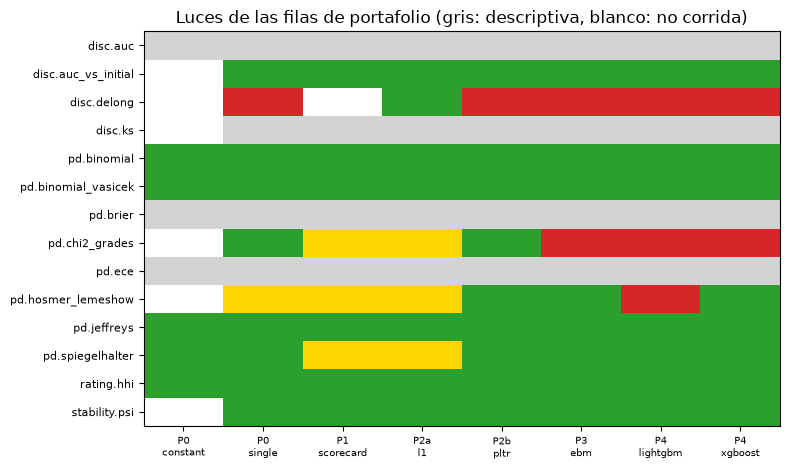

In [5]:
# Dibujar las luces de las filas de portafolio como una grilla
from matplotlib.colors import ListedColormap

codes = {"missing": 0, "not_evaluated": 1, "green": 2, "amber": 3, "red": 4}
grid = np.zeros((len(board), len(rungs)))
for i, test_id in enumerate(board):
    for j, r in enumerate(rungs):
        row = portfolio_row(holdout, test_id, r)
        grid[i, j] = codes["missing"] if row is None else codes[row["light"]]
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.imshow(grid, cmap=ListedColormap(["white", "lightgray", "tab:green", "gold", "tab:red"]), vmin=0, vmax=4, aspect="auto")
ax.set_xticks(range(len(rungs)))
ax.set_xticklabels([r.split("-")[0] + "\n" + r.split("-")[-1] for r in rungs], fontsize=7)
ax.set_yticks(range(len(board)))
ax.set_yticklabels(board, fontsize=8)
ax.set_title("Luces de las filas de portafolio (gris: descriptiva, blanco: no corrida)")
fig.tight_layout()
plt.show()


### Paso 3: discriminación

La primera familia pregunta si la PD ordena a los incumplidos por encima de los no incumplidos. Tres pruebas pertenecen a ella. El AUC es descriptivo. La **prueba de DeLong** (DeLong, DeLong y Clarke-Pearson, 1988) compara el AUC de dos modelos puntuados sobre las mismas tarjetas, que están correlacionados, así que necesita la covarianza de las dos curvas; su estadístico es la diferencia de AUC sobre su error estándar:

$$z = \frac{\widehat{\mathrm{AUC}}_1 - \widehat{\mathrm{AUC}}_2}{\sqrt{\widehat{\mathrm{Var}}(\widehat{\mathrm{AUC}}_1 - \widehat{\mathrm{AUC}}_2)}}$$

y el valor p es bilateral sobre una normal estándar. Las filas versionadas llevan los dos AUC, su diferencia y su varianza en `extras`. La siguiente celda los imprime y recalcula $z$ y el valor p desde esos números. También muestra contra qué modelo compara cada fila: el segundo AUC es el de la tarjeta de puntaje en todas las filas. Luego el **AUC contra desarrollo** (ECB 2019, sección 2.5.4.1): unilateral, rechaza cuando el AUC cayó desde el desarrollo; las filas versionadas suman la varianza del AUC de desarrollo al estadístico, una extensión que el motor anota en su campo `notes`.

In [6]:
# Recalcular el estadístico de DeLong y el valor p de cada fila versionada desde sus AUC y la varianza de su diferencia
print(f"{'modelo':14s} {'AUC 1':>7s} {'AUC 2':>7s} {'dif.':>8s} {'z':>7s} {'z recalculado':>16s} {'p versionado':>14s} {'p recalculado':>14s}")
for r in rungs:
    row = portfolio_row(holdout, "disc.delong", r)
    if row is None:
        continue
    e = row["extras"]
    z = e["difference"] / np.sqrt(e["variance"])
    print(f"{r:14s} {e['auc_1']:7.4f} {e['auc_2']:7.4f} {e['difference']:8.4f} {row['statistic']:7.2f} {z:16.2f} {row['p_value']:14.3g} {2 * stats.norm.sf(abs(z)):14.3g}")


modelo           AUC 1   AUC 2     dif.       z    z recalculado   p versionado  p recalculado
P0-single       0.6917  0.7587  -0.0670  -13.35           -13.35       1.26e-40       1.26e-40
P2a-l1          0.7587  0.7587  -0.0000   -1.70            -1.70         0.0884         0.0884
P2b-pltr        0.7749  0.7587   0.0162    6.67             6.67       2.58e-11       2.58e-11
P3-ebm          0.7746  0.7587   0.0159    6.31             6.31       2.74e-10       2.74e-10
P4-lightgbm     0.7770  0.7587   0.0183    7.19             7.19       6.53e-13       6.53e-13
P4-xgboost      0.7755  0.7587   0.0168    7.02             7.02       2.18e-12       2.18e-12


El AUC contra desarrollo. La siguiente celda recalcula el estadístico de la tarjeta de puntaje desde los extras versionados, y luego llama a las dos pruebas de discriminación del motor sobre la muestra de 50 tarjetas: el AUC contra desarrollo con el AUC y la varianza de desarrollo versionados, y DeLong entre el puntaje de la máquina de boosting y la PD de la tarjeta de puntaje.

In [7]:
# El AUC contra desarrollo: recalcular el estadístico de la tarjeta de puntaje desde los extras versionados, y luego llamar al motor sobre la muestra de 50 tarjetas
row = portfolio_row(holdout, "disc.auc_vs_initial", "P1-scorecard")
e = row["extras"]
z = (e["auc_initial"] - e["auc_current"]) / np.sqrt(e["s2_total"])
print("AUC en desarrollo:", round(e["auc_initial"], 4), "| AUC ahora:", round(e["auc_current"], 4))
print("varianza del AUC actual:", f"{e['s2']:.3g}", "| del AUC de desarrollo:", f"{e['auc_initial_variance']:.3g}", "| total:", f"{e['s2_total']:.3g}")
print("z recalculado:", round(float(z), 4), "| versionado:", round(row["statistic"], 4), "| p unilateral:", round(float(stats.norm.sf(z)), 4), "| versionado:", round(row["p_value"], 4))

from riskvalidation.validation import disc_auc_vs_initial, disc_delong

sample = holdout["outputs"]["sample"]
y50 = np.array(sample["targets"])
pd50 = np.array(sample["scorecard_pd"])
ebm50 = np.array(sample["ebm_logit"])
small = disc_auc_vs_initial(e["auc_initial"], pd50, y50, auc_initial_variance=e["auc_initial_variance"], policy=policy, model_id="P1-scorecard")
print("motor sobre 50 tarjetas, AUC contra desarrollo: p", round(small.p_value, 4), "|", LIGHT[small.light.value])
duo = disc_delong(ebm50, pd50, y50, policy=policy, model_id="P3-ebm")
print("motor sobre 50 tarjetas, DeLong EBM contra tarjeta de puntaje: AUC", round(duo.extras["auc_1"], 4), "frente a", round(duo.extras["auc_2"], 4), "| p", round(duo.p_value, 3), "|", LIGHT[duo.light.value])


AUC en desarrollo: 0.7673 | AUC ahora: 0.7587
varianza del AUC actual: 4.17e-05 | del AUC de desarrollo: 8.78e-05 | total: 0.000129
z recalculado: 0.7529 | versionado: 0.7529 | p unilateral: 0.2257 | versionado: 0.2257
motor sobre 50 tarjetas, AUC contra desarrollo: p 0.5476 | verde
motor sobre 50 tarjetas, DeLong EBM contra tarjeta de puntaje: AUC 0.7695 frente a 0.7752 | p 0.866 | verde


### Paso 4: calibración, el nivel y el ajuste

La segunda familia pregunta si las PD tienen el tamaño correcto. Son dos preguntas, y la batería hace ambas:

- **el nivel**: ¿es correcta la PD promedio del portafolio? La prueba de Jeffreys, la binomial y la binomial ajustada por Vasicek toman el número de tarjetas, el de incumplimientos y la PD media (cuaderno 03 del tema 01). Son unilaterales: rechazan cuando los incumplimientos superan lo que permite la PD.
- **el ajuste**: ¿se ajusta la PD a los resultados grupo por grupo? El chi-cuadrado sobre grados (documento de trabajo 14 del BCBS), Hosmer-Lemeshow y Spiegelhalter lo preguntan, y pueden fallar aun cuando el promedio sea correcto, porque una PD demasiado alta para unos deudores y demasiado baja para otros se cancela en el promedio.

La siguiente celda toma los 12 grados de la tarjeta de puntaje que el artefacto de la muestra reservada versiona, descarta los vacíos y llama al motor sobre ellos. La prueba de Jeffreys corre una vez por grado (las filas `G05`, `G06`, ...) y el chi-cuadrado corre una vez sobre todos los grados (la fila `portfolio`). Ambos se comparan con las filas versionadas.

In [8]:
# Llamar al motor sobre la tabla de grados versionada y comparar con las filas versionadas a nivel de grado y de portafolio
from riskvalidation.validation import pd_chi2_grades, pd_jeffreys

grades = [g for g in holdout["outputs"]["rungs"]["P1-scorecard"]["grades"] if g["n"] > 0]
print(f"{'grado':7s} {'tarjetas':>7s} {'incumpl.':>9s} {'PD media':>8s} {'p motor':>11s} {'p versionado':>14s} {'luz':>6s}")
for g in grades:
    result = pd_jeffreys(n=g["n"], d=g["d"], pd=g["pd"], policy=policy, model_id="P1-scorecard", segment=g["grade"])
    committed = next(t for t in tests if t["test_id"] == "pd.jeffreys" and t["model_id"] == "P1-scorecard" and t["segment"] == g["grade"])
    print(f"{g['grade']:7s} {g['n']:7d} {g['d']:9d} {g['pd']:8.4f} {result.p_value:11.4f} {committed['p_value']:14.4f} {LIGHT[result.light.value]:>6s}")

chi = pd_chi2_grades([g["n"] for g in grades], [g["d"] for g in grades], [g["pd"] for g in grades], policy=policy, model_id="P1-scorecard", segment="portfolio")
chi_committed = portfolio_row(holdout, "pd.chi2_grades", "P1-scorecard")
print("chi-cuadrado sobre grados: T", round(chi.statistic, 4), "| grados de libertad", chi.extras["dof"], "| p", round(chi.p_value, 4), "| versionado", round(chi_committed["p_value"], 4), "|", LIGHT[chi.light.value])


grado   tarjetas  incumpl. PD media     p motor   p versionado    luz
G05          68         4   0.0468      0.2953         0.2953  verde
G06         698        54   0.0653      0.1005         0.1005  verde
G07        1862       155   0.0950      0.9607         0.9607  verde
G08        3101       466   0.1399      0.0494         0.0494  ámbar
G09        1224       251   0.1990      0.2957         0.2957  verde
G10         719       251   0.3241      0.0770         0.0770  verde
G11         510       251   0.4762      0.2348         0.2348  verde
G12         818       559   0.7243      0.9952         0.9952  verde
chi-cuadrado sobre grados: T 17.3737 | grados de libertad 8 | p 0.0264 | versionado 0.0264 | ámbar


### Paso 5: Hosmer-Lemeshow, abierto

Hosmer-Lemeshow ordena las tarjetas por PD, las corta en $G$ grupos de igual tamaño y compara, en el grupo $g$ con $m_g$ tarjetas, los incumplimientos observados $O_g$ con los esperados $E_g$ (la suma de las PD del grupo; Hosmer y Lemeshow, 1980):

$$\mathrm{HL} = \sum_{g=1}^{G} \frac{(O_g - E_g)^2}{E_g\,(1 - E_g / m_g)}$$

La distribución de referencia es $\chi^2$ con $G$ grados de libertad cuando las PD se fijaron antes de los resultados, como en una muestra de validación (la fila versionada tiene `fitted` falso y 10 grados de libertad). Los tramos de confiabilidad del artefacto son exactamente esos grupos: diez tramos de 900 tarjetas por PD, cada uno con su PD media y su tasa de incumplimiento observada. La siguiente celda construye $O_g$ y $E_g$ desde ellos, imprime cada término y compara la suma y su valor p con la fila versionada.

In [9]:
# Reconstruir el estadístico de Hosmer-Lemeshow desde los diez tramos de confiabilidad, término a término
reliability = holdout["outputs"]["rungs"]["P1-scorecard"]["reliability"]
m_g = np.array([b["n"] for b in reliability], dtype=float)
expected = np.array([b["pd"] for b in reliability]) * m_g
observed = np.array([b["dr"] for b in reliability]) * m_g
terms = (observed - expected) ** 2 / (expected * (1.0 - expected / m_g))
print(f"{'g':>2s} {'m_g':>5s} {'O_g':>7s} {'E_g':>7s} {'término':>8s}")
for g_, (m_, o_, e_, t_) in enumerate(zip(m_g, observed, expected, terms), start=1):
    print(f"{g_:2d} {m_:5.0f} {o_:7.1f} {e_:7.1f} {t_:8.3f}")
hl_row = portfolio_row(holdout, "pd.hosmer_lemeshow", "P1-scorecard")
print("HL desde los tramos:", round(float(terms.sum()), 4), "| versionado:", round(hl_row["statistic"], 4))
print("p (chi2, 10 grados de libertad):", round(float(stats.chi2.sf(terms.sum(), hl_row["extras"]["dof"])), 4), "| versionado:", round(hl_row["p_value"], 4), "|", LIGHT[hl_row["light"]])


 g   m_g     O_g     E_g  término
 1   900    68.0    59.1    1.430
 2   900    73.0    79.0    0.503
 3   900    77.0    95.8    4.142
 4   900   105.0   110.6    0.321
 5   900   140.0   123.7    2.496
 6   900   140.0   136.4    0.110
 7   900   187.0   157.0    6.922
 8   900   225.0   211.5    1.133
 9   900   367.0   359.8    0.240
10   900   609.0   638.6    4.723
HL desde los tramos: 22.0205 | versionado: 22.0205
p (chi2, 10 grados de libertad): 0.015 | versionado: 0.015 | ámbar


El diagrama de confiabilidad de la tarjeta de puntaje y del escalón LightGBM calibrado: los diez tramos de 900 tarjetas, PD media frente a tasa de incumplimiento observada, con la diagonal como calibración perfecta.

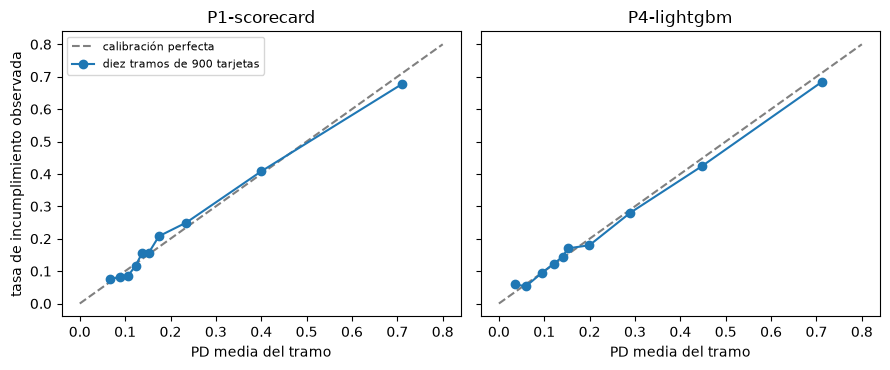

In [10]:
# Dibujar el diagrama de confiabilidad de la tarjeta de puntaje y del escalón LightGBM calibrado
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for ax, rung in zip(axes, ("P1-scorecard", "P4-lightgbm")):
    bins_ = holdout["outputs"]["rungs"][rung]["reliability"]
    ax.plot([0, 0.8], [0, 0.8], color="gray", linestyle="--", label="calibración perfecta")
    ax.plot([b["pd"] for b in bins_], [b["dr"] for b in bins_], marker="o", label="diez tramos de 900 tarjetas")
    ax.set_xlabel("PD media del tramo")
    ax.set_title(rung)
axes[0].set_ylabel("tasa de incumplimiento observada")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()


El puntaje de Brier y el error de calibración esperado (ECE) resumen los mismos tramos en un número cada uno y son descriptivos en la política por defecto. El puntaje de Brier es el error cuadrático medio de la PD como pronóstico; el ECE es la brecha absoluta media ponderada entre la PD media y la tasa observada por tramo. La siguiente celda imprime ambos para los ocho escalones, con la marca propia del motor sobre si la descomposición del Brier en confiabilidad, resolución e incertidumbre es exacta (no lo es para PD continuas).

In [11]:
# Imprimir el puntaje de Brier y el error de calibración esperado de los ocho escalones
print(f"{'modelo':14s} {'Brier':>7s} {'ECE':>7s} {'descomposición exacta':>26s}")
for r in rungs:
    brier = portfolio_row(holdout, "pd.brier", r)
    ece = portfolio_row(holdout, "pd.ece", r)
    print(f"{r:14s} {brier['metric']:7.4f} {ece['metric']:7.4f} {str(si_no(brier['extras']['decomposition_exact'])):>26s}")


modelo           Brier     ECE      descomposición exacta
P0-constant     0.1723  0.0174                         sí
P0-single       0.1431  0.0144                         no
P1-scorecard    0.1393  0.0155                         no
P2a-l1          0.1393  0.0153                         no
P2b-pltr        0.1367  0.0113                         no
P3-ebm          0.1367  0.0118                         no
P4-lightgbm     0.1361  0.0134                         no
P4-xgboost      0.1359  0.0124                         no


### Paso 6: estabilidad

La tercera familia compara la población de ahora con la del desarrollo. El índice de estabilidad de la población (PSI) de la distribución de la PD toma diez tramos fijados sobre las tarjetas de desarrollo, aquí las 16.800 tarjetas de entrenamiento, y compara la proporción de las 9.000 tarjetas reservadas en cada uno; con la cota chi-cuadrado de Yurdakul y Naranjo (2020) tiene un valor p, y `benchmark_05` es el PSI sobre el cual rechazaría al 5%. El mismo índice sobre cada variable de entrada es el índice de estabilidad de característica (CSI), una fila por variable. El índice de Herfindahl de los grados (`rating.hhi`) pregunta si los grados se concentran más que en desarrollo. La siguiente celda imprime el PSI de la tarjeta de puntaje con sus contribuciones por tramo, las luces de las 20 filas de CSI y la fila de concentración.

In [12]:
# Imprimir el PSI con sus contribuciones por tramo, las luces de CSI y la fila de concentración de la tarjeta de puntaje
psi = portfolio_row(holdout, "stability.psi", "P1-scorecard")
e = psi["extras"]
print("PSI:", round(psi["metric"], 6), "| p:", round(psi["p_value"], 4), "|", LIGHT[psi["light"]], "| PSI crítico al 5%:", round(e["benchmark_05"], 5))
print("tarjetas de desarrollo:", e["n"], "| tarjetas reservadas:", e["m"], "| tramos:", e["bins"])
print("contribución por tramo:", [round(c, 5) for c in e["contributions"]])
csi = [t for t in tests if t["test_id"] == "stability.csi"]
lights = {}
for t in csi:
    lights[LIGHT[t["light"]]] = lights.get(LIGHT[t["light"]], 0) + 1
print("CSI: ", len(csi), "filas, luces", lights)
hhi = portfolio_row(holdout, "rating.hhi", "P1-scorecard")
print("concentración de grados, índice de Herfindahl ahora y en desarrollo:", round(hhi["extras"]["hi_current"], 4), round(hhi["extras"]["hi_initial"], 4), "| p", round(hhi["p_value"], 3), "|", LIGHT[hhi["light"]])


PSI: 0.000952 | p: 0.7812 | verde | PSI crítico al 5%: 0.00289
tarjetas de desarrollo: 16800 | tarjetas reservadas: 9000 | tramos: 10
contribución por tramo: [0.0002, 0.0, 0.0, 0.00027, 0.0, 0.00017, 7e-05, 0.0, 0.00018, 6e-05]
CSI:  20 filas, luces {'verde': 20}
concentración de grados, índice de Herfindahl ahora y en desarrollo: 0.3602 0.3588 | p 0.497 | verde


### Paso 7: qué nota cada prueba

La misma tarjeta de puntaje, la misma batería, tres conjuntos de evaluación: la muestra reservada tal cual, la muestra reservada con una deriva moderada de las entradas, y la muestra reservada con la tasa de incumplimiento multiplicada por 1,5. La siguiente celda pone lado a lado las filas de portafolio de la tarjeta de puntaje. Una batería sirve solo si sus pruebas notan cosas distintas, y esta tabla es la evidencia de cuáles notan qué.

In [13]:
# Poner lado a lado las filas de portafolio de la tarjeta de puntaje en los tres conjuntos de evaluación
variants = (("holdout", holdout), ("drift-moderate", drift), ("prior-shift", prior))
print(f"{'test':22s}" + "".join(f"{name:>20s}" for name, _ in variants))
for test_id in board:
    line = f"{test_id:22s}"
    for _, doc in variants:
        row = portfolio_row(doc, test_id, "P1-scorecard")
        if row is None:
            line += f"{'-':>20s}"
            continue
        value = row["p_value"] if row["p_value"] is not None else row["metric"]
        line += f"{value:14.3g}/{LIGHT[row['light']][:3]:<4s}"
    print(line)
print("incumplimientos:", {name: doc["outputs"]["defaults"] for name, doc in variants})


test                               holdout      drift-moderate         prior-shift
disc.auc                       0.759/s/l          0.784/s/l          0.769/s/l 
disc.auc_vs_initial            0.226/ver          0.938/ver          0.558/ver 
disc.delong                              -                   -                   -
disc.ks                    8.14e-220/s/l      5.54e-321/s/l      4.98e-311/s/l 
pd.binomial                    0.314/ver          0.732/ver       1.08e-78/roj 
pd.binomial_vasicek            0.454/ver          0.493/ver           0.09/ver 
pd.brier                       0.139/s/l          0.147/s/l           0.18/s/l 
pd.chi2_grades                0.0264/ámb       5.57e-05/roj      3.09e-108/roj 
pd.ece                        0.0155/s/l         0.0143/s/l         0.0879/s/l 
pd.hosmer_lemeshow             0.015/ámb        0.00163/roj      2.19e-109/roj 
pd.jeffreys                     0.31/ver          0.728/ver       8.67e-79/roj 
pd.spiegelhalter              0.02

## Resultados

- **La batería es una tabla con dos tipos de fila.** 187 filas sobre ocho modelos y 15 ids de prueba: 105 a nivel de portafolio, 62 a nivel de grado (la prueba de Jeffreys por grado) y 20 de estabilidad por característica de las entradas. Once ids de prueba tienen umbral en la política por defecto; AUC, KS, Brier y ECE solo describen.
- **Las filas versionadas son las filas del motor.** Llamado sobre la tabla de grados versionada, el motor devuelve el mismo valor p de Jeffreys para cada uno de los ocho grados y el mismo chi-cuadrado sobre grados (T cerca de 17,4 con 8 grados de libertad, p 0,026); el estadístico de Hosmer-Lemeshow reconstruido término a término desde los diez tramos de confiabilidad es 22,02, el valor versionado, con p 0,015 con 10 grados de libertad.
- **Ordenar y dimensionar son preguntas distintas.** La tarjeta de puntaje ordena tan bien como el modelo logístico con penalización (P2a: DeLong p 0,09, sin diferencia) y peor que los cuatro modelos más ricos: los árboles penalizados, la máquina de boosting explicable y los dos modelos de árboles con boosting suben el AUC en 0,016 a 0,018, y DeLong es rojo contra la tarjeta de puntaje en los cuatro. Sin embargo, en el nivel todos los modelos están en verde: las pruebas de Jeffreys, binomial y Vasicek aceptan la PD media de cada escalón.
- **Las pruebas de ajuste discrepan de las de nivel, y entre ellas.** La tarjeta de puntaje está en verde en el nivel y en ámbar en Hosmer-Lemeshow, Spiegelhalter y el chi-cuadrado sobre grados: el promedio es correcto y algunos grados no (la prueba de Jeffreys deja a G08 en ámbar, p 0,049). La máquina de boosting explicable y los dos escalones con boosting son el caso contrario para el chi-cuadrado sobre grados (rojo, p 0,0007 o menos), mientras que su prueba de Spiegelhalter está en verde y solo LightGBM está en rojo en Hosmer-Lemeshow. Las pruebas responden preguntas distintas, y quien valida las lee juntas antes de concluir que "la calibración está mal".
- **La estabilidad es silenciosa en la muestra reservada y ruidosa en los desplazamientos.** El PSI de la tarjeta de puntaje es 0,00095, bajo su valor crítico del 5% de 0,0029, y las 20 filas de CSI dicen que nada cambió, como se espera de una muestra reservada aleatoria. Con las entradas derivadas el PSI es rojo (p cerca de 3e-36) y las pruebas de ajuste caen (chi-cuadrado y Hosmer-Lemeshow rojos), pero las pruebas de nivel siguen en verde y el AUC contra desarrollo sigue en verde; con la tasa de incumplimiento multiplicada por 1,5 las pruebas de nivel (Jeffreys, binomial) se vuelven rojas de inmediato, y la binomial ajustada por Vasicek sigue en verde (p 0,09), siendo el precio de admitir correlación la potencia.

Lo que este cuaderno no muestra: los umbrales son la convención de la política por defecto (cuaderno 03 del tema 01), no regulación, así que un ámbar es una bandera y no un veredicto. Las 62 filas por grado son pruebas de Jeffreys de grados con unos cientos de tarjetas cada uno, y la prueba tiene poca potencia ahí. Las variantes `small-sample` y `label-noise` y el gemelo alemán son otras variantes de la misma batería.

## Resumen

- Una batería, 15 ids de prueba, ocho modelos: las filas de portafolio llevan el titular, las filas de grado ubican el problema, las filas de característica vigilan las entradas.
- Una fila versionada es reproducible: el motor la devuelve desde la tabla de grados, y Hosmer-Lemeshow sale de diez tramos de confiabilidad con la fórmula de este cuaderno.
- Discriminación, nivel, ajuste y estabilidad son familias separadas; un modelo puede estar verde en una y ámbar en otra, y la prueba de DeLong, no el AUC solo, dice si un retador ordena mejor.
- Las variantes desplazadas muestran que las pruebas notan desplazamientos distintos: una deriva de las entradas llega al PSI y a las pruebas de ajuste, un cambio de la tasa de incumplimiento llega primero a las pruebas de nivel.

**Qué probar después.** Lee la misma tabla para `small-sample.json` y compara las pruebas de ajuste con las de la muestra reservada: ¿qué cambia cuando la muestra es menor? Luego continúa con el cuaderno 04, que valida fuera del tiempo.

## Referencias

- DeLong, E. R., DeLong, D. M. y Clarke-Pearson, D. L. (1988), Comparing the areas under two or more correlated receiver operating characteristic curves: a nonparametric approach, Biometrics 44(3). https://doi.org/10.2307/2531595
- Hosmer, D. W. y Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Yurdakul, B. y Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4). https://doi.org/10.21314/JRMV.2020.227
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revisado): la binomial, la binomial ajustada por Vasicek y el chi-cuadrado sobre grados. https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, secciones 2.5.3.1 y 2.5.4.1 y Anexo 1 (sección 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Brown, L. D., Cai, T. T. y DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- Yeh, I-C. (2009), Default of Credit Card Clients, UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients